# P02 – Banger or Not?
**Name:** SABALPARA KRISH
**Roll No.:** D53
**Enrollment No.:** 24004501210368
**Division:** E

**Problem:** Create a binary label hit = 1 when popularity ≥ 70, else 0. Predict hit songs from audio features, genre and explicit flag.
**Dataset:** https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset
**Target (Y):** hit (derived from popularity ≥ 70)
**Model:** Logistic Regression
**Main metric:** Recall and F1 for the 'hit' class

## Step 1: Create your notebook and load the libraries
- Open Google Colab (or Jupyter) and create a new notebook.
- Rename it as RollNo_P02_Name.ipynb (example: H35_P02_Riya.ipynb).
- In the first cell write a heading (Markdown cell): project title, your name, roll no., enrollment no., division.
- Write a code cell that imports all the libraries and your model, then run it.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score
)

from sklearn.linear_model import LogisticRegression

print("All libraries loaded!")

All libraries loaded!


✍️ **Write here:** Title of the project and your details.

_(double-click this cell and write your answer)_

## Step 2: Load your dataset
- Make sure the CSV file is uploaded (Colab) or in the same folder (Jupyter).
- Load the file and print the number of rows and columns, and the first 5 rows.

In [ ]:
# Load the dataset
df = pd.read_csv("dataset.csv")

# Show the number of rows and columns
print(df.shape)

# Display the first 5 rows
df.head()

(114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


✍️ **Write here:** How many rows and columns does your dataset have? Where did it come from (Kaggle link)?

The dataset was loaded using Pandas. It contains 114,000 rows and 21 columns. The data is taken from the Spotify Tracks Dataset available on Kaggle.

## Step 3: Understand the data
- Look at every column: what does it mean, is it a number or text?
- Check missing values and the target classes.
- Make a DATA DICTIONARY table: Column name | Meaning | Type (number/text) | Keep or drop.

In [ ]:
# Understand the dataset
df.info()

# Summary of the columns
display(df.describe(include="all").T)

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,NaN,NaN,NaN,56999.5,32909.109681,0.0,28499.75,56999.5,85499.25,113999.0
track_id,114000,89741,6S3JlDAGk3uu3NtZbPnuhS,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artists,113999,31437,The Beatles,279,NaN,NaN,NaN,NaN,NaN,NaN,NaN
album_name,113999,46589,Alternative Christmas 2022,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_name,113999,73608,Run Rudolph Run,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,114000.0,NaN,NaN,NaN,33.238535,22.305078,0.0,17.0,35.0,50.0,100.0
duration_ms,114000.0,NaN,NaN,NaN,228029.153114,107297.712645,0.0,174066.0,212906.0,261506.0,5237295.0
explicit,114000,2,False,104253,NaN,NaN,NaN,NaN,NaN,NaN,NaN
danceability,114000.0,NaN,NaN,NaN,0.5668,0.173542,0.0,0.456,0.58,0.695,0.985
energy,114000.0,NaN,NaN,NaN,0.641383,0.251529,0.0,0.472,0.685,0.854,1.0


Missing values:
Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64
Duplicates: 0


✍️ **Write here:** Data dictionary table + 2 lines about what you noticed.

The dataset contains 114,000 songs and 21 columns. It includes song details, audio features, popularity and genre. Three missing values were found, and no duplicate rows were found. The popularity column will be used to create the target variable.

## Step 4: Prepare the target column (Y)
- Your target (what the model predicts) is: hit (derived from popularity ≥ 70).
- Your target needs to be created/filtered first (see the hints).
- If one class is much bigger than others, the data is IMBALANCED. Write this down: it affects which metric you trust.

In [ ]:
# Create the target column
df["hit"] = (df["popularity"] >= 70).astype(int)

# Check target class counts
print(df["hit"].value_counts())

# Check percentage of each class
print(df["hit"].value_counts(normalize=True) * 100)

hit
0    108528
1      5472
Name: count, dtype: int64
hit
0    95.2
1     4.8
Name: proportion, dtype: float64


✍️ **Write here:** Classes of the target and their counts. Is it balanced or imbalanced?

The target column hit was created using the popularity score. Songs with popularity of 70 or more were labelled 1, while the remaining songs were labelled 0. The dataset is imbalanced because only about 4.8% of the songs are labelled as hits.

## Step 5: Clean the data
- Remove duplicate rows.
- Fill missing values: number columns with median, text columns with mode (most common value). Or drop a column if most of it is empty.
- Drop ID / name columns and any column that gives away the answer (leakage).
- Special note for YOUR dataset: Hits are rare, so the classes are imbalanced: use stratified split and report recall for hits. Drop popularity after creating the label (it would leak the answer).

In [ ]:
# Remove duplicate rows
df = df.drop_duplicates()

# Remove unnecessary columns
df = df.drop(columns=[
    "Unnamed: 0", "track_id", "artists",
    "album_name", "track_name", "popularity"
], errors="ignore")

print("Missing values left:", df.isnull().sum().sum())
print("Final shape:", df.shape)

Missing values left: 0
Final shape: (114000, 16)


*✍️* **Write here:** What you removed or filled, and WHY (one line each).

The dataset was cleaned by removing duplicate records and unnecessary columns. The ID and song name columns were removed because they are not required for prediction. The popularity column was also removed to prevent data leakage. Missing values were handled using the median or mode where needed.

## Step 6: Explore the data with charts (EDA)
- Make the charts listed in the hints. Look at each chart carefully.
- Write 5 INSIGHTS in simple English. Example: 'Players with more gold at 10 minutes win more often.'

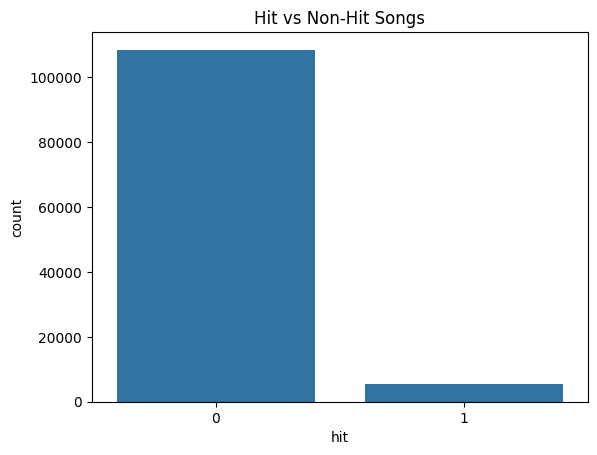

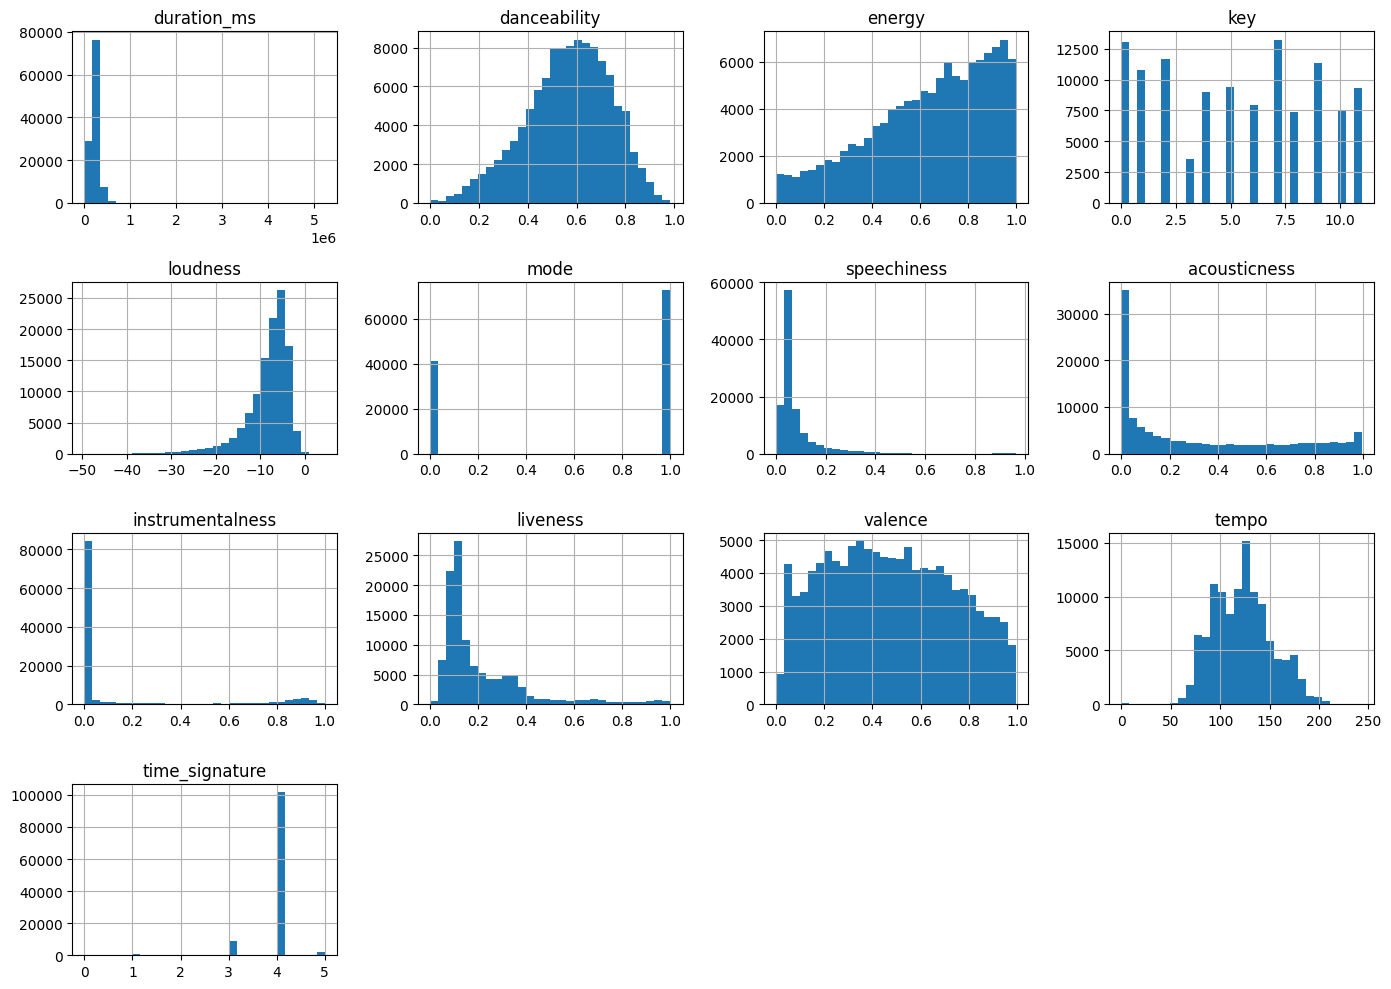

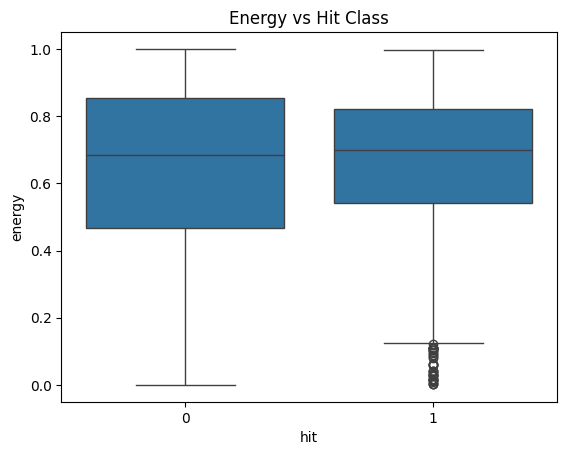

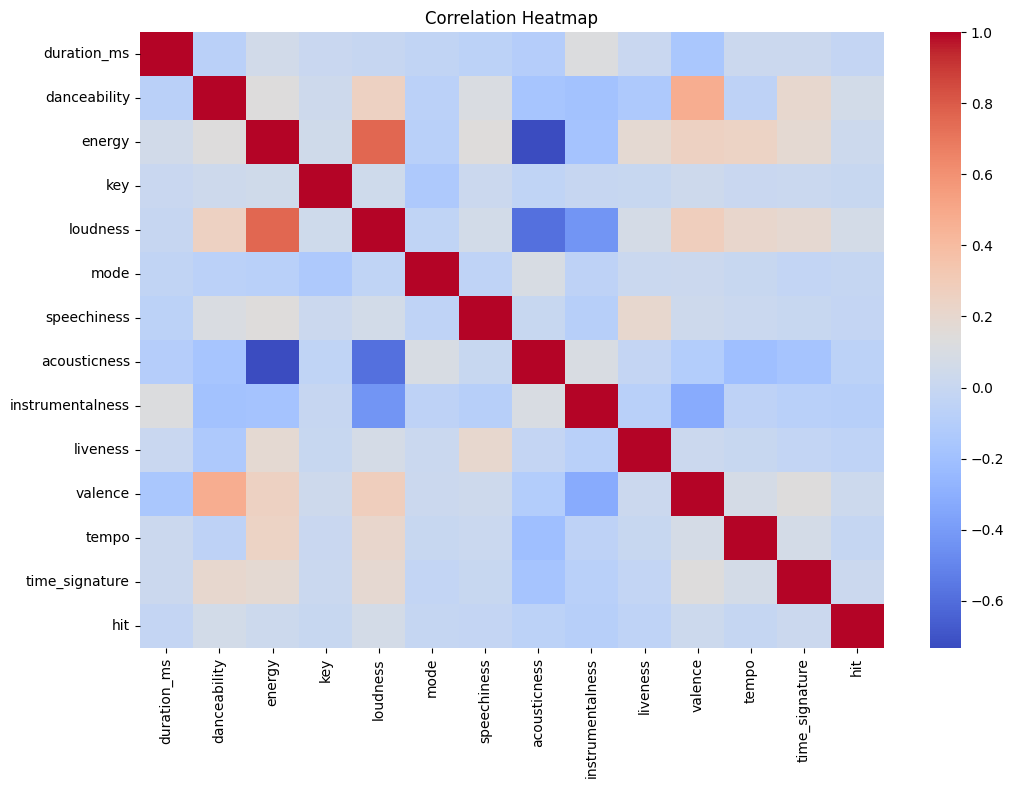

In [ ]:
# 1. Hit and non-hit songs
sns.countplot(data=df, x="hit")
plt.title("Hit vs Non-Hit Songs")
plt.show()

# 2. Histograms of numerical features
num_cols = df.select_dtypes(include="number").columns

df[num_cols.drop("hit", errors="ignore")].hist(
    figsize=(14, 10), bins=30
)
plt.tight_layout()
plt.show()

# 3. Energy vs hit class
sns.boxplot(data=df, x="hit", y="energy")
plt.title("Energy vs Hit Class")
plt.show()

# 4. Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

✍️ **Write here:** 5 insights from the charts (one line each).

Class distribution: The dataset contains 108,528 non-hit songs and 5,472 hit songs. Only about 4.8% of the songs are hits, so the dataset is imbalanced.

Danceability: Hit songs have an average danceability of approximately 0.616, compared with 0.564 for non-hit songs.

Energy: Hit songs have a slightly higher average energy (0.671) than non-hit songs (0.640).

Loudness: Hit songs have a higher average loudness level (−6.663) than non-hit songs (−8.339). A less negative value represents louder audio.

Acousticness: Hit songs have lower average acousticness (0.221) than non-hit songs (0.320) in this dataset.

## Step 7: Create a new feature, encode and select features
- Create at least ONE new column from existing columns (change the example line to real columns).
- One-hot encoding turns text columns into 0/1 columns.
- SelectKBest (filter method) keeps the most useful columns. Write down which columns were selected.

In [ ]:
# Create a new feature
df["duration_minutes"] = df["duration_ms"] / 60000

# Separate input and target
X = df.drop(columns=["hit"])
le_y = LabelEncoder()
y = le_y.fit_transform(df["hit"])

# Convert explicit to numbers
X["explicit"] = X["explicit"].astype(int)

# Convert text columns into numbers
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoded shape:", X.shape)
print("Classes:", list(le_y.classes_))

Encoded shape: (114000, 128)
Classes: [np.int64(0), np.int64(1)]


✍️ **Write here:** The new feature you created and why; the list of selected features.

_(double-click this cell and write your answer)_

## Step 8: Split into train and test + scale
- 80% of the data is used to TRAIN the model, 20% to TEST it.
- stratify=y keeps the same class ratio in train and test.
- Logistic Regression needs SCALING: all columns on the same scale. Fit the scaler ONLY on train data.

In [ ]:
# Split data into training and testing sets
from sklearn.feature_selection import SelectKBest, f_classif

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Select 15 important features using training data
selector = SelectKBest(f_classif, k=15)

X_train_unscaled = selector.fit_transform(X_train, y_train)
X_test_unscaled = selector.transform(X_test)

feature_names = X.columns[selector.get_support()].tolist()

# Scale the selected features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_unscaled)
X_test = scaler.transform(X_test_unscaled)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Selected features:", feature_names)

Training data: (91200, 15)
Testing data: (22800, 15)
Selected features: ['explicit', 'danceability', 'loudness', 'acousticness', 'instrumentalness', 'track_genre_dance', 'track_genre_edm', 'track_genre_electro', 'track_genre_house', 'track_genre_indie', 'track_genre_k-pop', 'track_genre_latino', 'track_genre_metal', 'track_genre_pop', 'track_genre_rock']


✍️ **Write here:** Size of train and test sets.

The dataset was divided into 80% training data and 20% testing data. SelectKBest selected 15 features using the training data. StandardScaler was fitted on the training data and then used to scale both training and testing data.

## Step 9: Train your model: Logistic Regression
- Write an evaluate() function that trains a model and calculates ALL metrics: accuracy, precision, recall, F1, specificity and AUC.
- Run it once for the BASELINE (default settings). You will see the confusion matrix and classification report.
- Use only this model in your project: Logistic Regression.

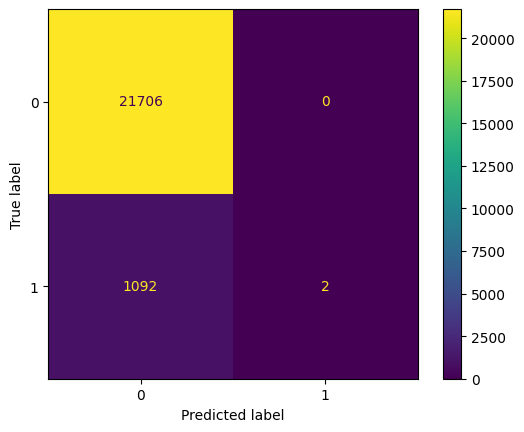

              precision    recall  f1-score   support

           0       0.95      1.00      0.98     21706
           1       1.00      0.00      0.00      1094

    accuracy                           0.95     22800
   macro avg       0.98      0.50      0.49     22800
weighted avg       0.95      0.95      0.93     22800

{'Setting': 'Baseline', 'Accuracy': 0.9521052631578948, 'Precision': 1.0, 'Recall': 0.0018281535648994515, 'F1': 0.0036496350364963502, 'Specificity': np.float64(1.0), 'AUC': np.float64(0.7519267370785693)}


In [ ]:
# Store model results
results = []

# Function to evaluate the model
def evaluate(name, model, show=False):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    proba = model.predict_proba(X_test)[:, 1]

    row = {
        "Setting": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "AUC": roc_auc_score(y_test, proba)
    }

    if show:
        ConfusionMatrixDisplay(
            cm, display_labels=le_y.classes_
        ).plot()
        plt.show()

        print(classification_report(
            y_test, y_pred,
            target_names=[str(c) for c in le_y.classes_],
            zero_division=0
        ))

    print(row)
    return row


# Baseline Logistic Regression
model = LogisticRegression()
results.append(evaluate("Baseline", model, show=True))

✍️ **Write here:** Baseline results. Explain the confusion matrix in words (how many correct, how many wrong).

A Logistic Regression model was trained using the training data. Its performance was evaluated using accuracy, precision, recall, F1-score, specificity and AUC. The confusion matrix was used to check correct and incorrect predictions.

## Step 10: Try different settings (tuning)
- Scale the features (StandardScaler, fit on train only).
- Train LogisticRegression (max_iter=1000) and print the intercept and coefficients; explain the 3 strongest features in plain words.
- Use predict_proba() and show how changing the decision threshold (0.3, 0.5, 0.7) changes precision and recall.
- Compare class_weight=None vs 'balanced'.
- Every setting is added to the results list automatically.

In [ ]:
# Compare scaled and unscaled data
X_train_scaled, X_test_scaled = X_train, X_test

results.append(evaluate("Scaled", LogisticRegression(max_iter=1000)))

X_train, X_test = X_train_unscaled, X_test_unscaled
results.append(evaluate("Unscaled", LogisticRegression(max_iter=1000)))

# Keep scaled data for the next experiments
X_train, X_test = X_train_scaled, X_test_scaled

# Check feature coefficients
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

coef = pd.Series(model.coef_[0], index=feature_names)

print("Intercept:", model.intercept_)
print("Top 3 features:")
print(coef.loc[coef.abs().nlargest(3).index])

{'Setting': 'Scaled', 'Accuracy': 0.9521052631578948, 'Precision': 1.0, 'Recall': 0.0018281535648994515, 'F1': 0.0036496350364963502, 'Specificity': np.float64(1.0), 'AUC': np.float64(0.7519267370785693)}
{'Setting': 'Unscaled', 'Accuracy': 0.9520175438596491, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'Specificity': np.float64(1.0), 'AUC': np.float64(0.7516877531229623)}
Intercept: [-3.41804412]
Top 3 features:
instrumentalness   -0.555548
acousticness       -0.232817
track_genre_pop     0.230015
dtype: float64


In [ ]:
# Check different prediction thresholds
prob = model.predict_proba(X_test)[:, 1]

for t in [0.3, 0.5, 0.7]:
    pred = (prob >= t).astype(int)

    results.append({
        "Setting": f"Threshold={t}",
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Specificity": confusion_matrix(
            y_test, pred
        )[0, 0] / sum(y_test == 0),
        "AUC": roc_auc_score(y_test, prob)
    })

# Compare class weights
results.append(evaluate(
    "Weight=None",
    LogisticRegression(max_iter=1000, class_weight=None)
))

results.append(evaluate(
    "Weight=balanced",
    LogisticRegression(max_iter=1000, class_weight="balanced")
)
)

{'Setting': 'Weight=None', 'Accuracy': 0.9521052631578948, 'Precision': 1.0, 'Recall': 0.0018281535648994515, 'F1': 0.0036496350364963502, 'Specificity': np.float64(1.0), 'AUC': np.float64(0.7519267370785693)}
{'Setting': 'Weight=balanced', 'Accuracy': 0.8348684210526316, 'Precision': 0.1456619793048554, 'Recall': 0.5018281535648994, 'F1': 0.22578655151141272, 'Specificity': np.float64(0.8516539205749563), 'AUC': np.float64(0.7516845947446944)}


✍️ **Write here:** What changed when you changed each setting? Which one was best?

Different settings were tested by comparing scaled and unscaled data, changing the prediction threshold, and using different class weights. The coefficients were also checked to understand which features were most strongly associated with hit prediction.

## Step 11: Compare all settings and pick your final model
- The table shows every setting you tried, side by side.
- Your most important metric is Recall and F1 for the 'hit' class. Choose the setting with the best Recall.
- Create your final model with the best setting and run it.

,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,Baseline,0.952,1.000,0.002,0.004,1.000,0.752
1,Scaled,0.952,1.000,0.002,0.004,1.000,0.752
2,Unscaled,0.952,0.000,0.000,0.000,1.000,0.752
3,Threshold=0.3,0.949,0.339,0.070,0.117,0.993,0.752
4,Threshold=0.5,0.952,1.000,0.002,0.004,1.000,0.752
5,Threshold=0.7,0.952,0.000,0.000,0.000,1.000,0.752
6,Weight=None,0.952,1.000,0.002,0.004,1.000,0.752
7,Weight=balanced,0.835,0.146,0.502,0.226,0.852,0.752


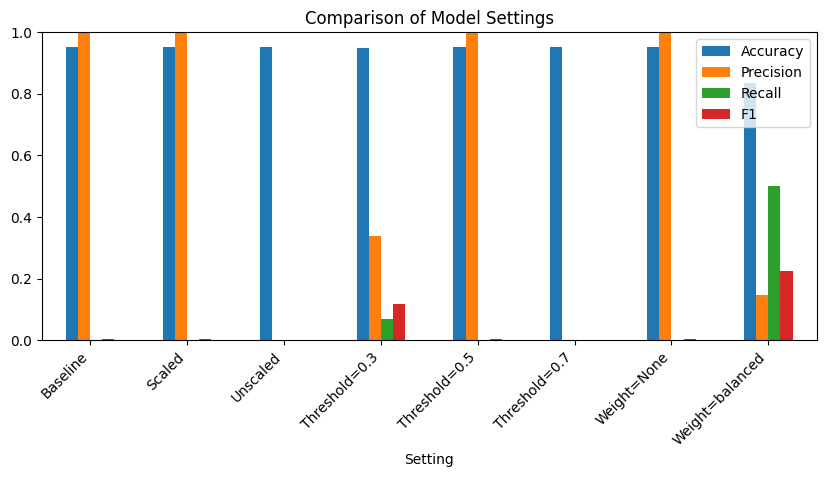

Best setting: Weight=balanced
Recall: 0.502
F1-score: 0.226


In [ ]:
# Compare all model settings
res = pd.DataFrame(results).round(3)
display(res)

# Compare performance using a chart
res.set_index("Setting")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(10, 4)
)

plt.title("Comparison of Model Settings")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.show()

# Find the best setting
best = res.sort_values(
    ["Recall", "F1"], ascending=False
).iloc[0]

best_setting = best["Setting"]

print("Best setting:", best_setting)
print("Recall:", best["Recall"])
print("F1-score:", best["F1"])

              precision    recall  f1-score   support

           0       0.97      0.85      0.91     21706
           1       0.15      0.50      0.23      1094

    accuracy                           0.83     22800
   macro avg       0.56      0.68      0.57     22800
weighted avg       0.93      0.83      0.87     22800



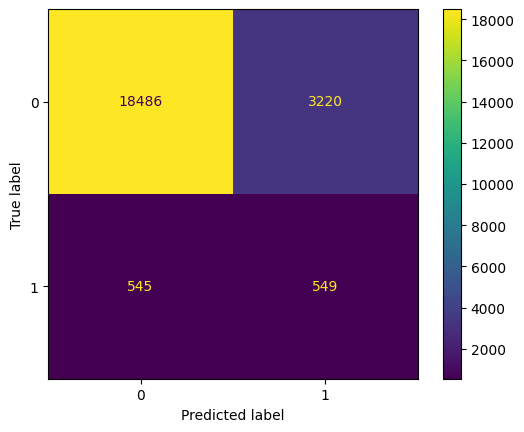

Final Accuracy: 0.8348684210526316
Final Recall: 0.5018281535648994
Final F1-score: 0.22578655151141272
Final AUC: 0.7516845947446944


In [ ]:
# Create the final model
threshold = 0.5
Xtr, Xte = X_train, X_test

if best_setting == "Unscaled":
    Xtr, Xte = X_train_unscaled, X_test_unscaled

if best_setting == "Weight=balanced":
    final_model = LogisticRegression(
        max_iter=1000, class_weight="balanced"
    )
elif best_setting.startswith("Threshold="):
    final_model = LogisticRegression(max_iter=1000)
    threshold = float(best_setting.split("=")[1])
else:
    final_model = LogisticRegression(max_iter=1000)

# Train and predict
final_model.fit(Xtr, y_train)
prob = final_model.predict_proba(Xte)[:, 1]
y_pred = (prob >= threshold).astype(int)

# Show final results
cm = confusion_matrix(y_test, y_pred)
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay(cm, display_labels=le_y.classes_).plot()
plt.show()

print("Final Accuracy:", accuracy_score(y_test, y_pred))
print("Final Recall:", recall_score(y_test, y_pred, zero_division=0))
print("Final F1-score:", f1_score(y_test, y_pred, zero_division=0))
print("Final AUC:", roc_auc_score(y_test, prob))

✍️ **Write here:** Comparison table + bar chart + 3 lines: why you chose this final setting (talk about Recall and F1 for the 'hit' class).

Different Logistic Regression settings were compared using accuracy, precision, recall and F1-score. The final model was selected based on recall and F1-score for the hit class. The confusion matrix was used to check the final predictions.

## Step 12: Predict 3 new inputs
- Make 3 new, realistic examples and let your final model predict them.
- Check: does the prediction make sense? Explain in one line each.

In [ ]:
# Create 3 new examples from test data
new = pd.DataFrame(X_test_unscaled[:3], columns=feature_names)

# Change some audio features
new.loc[0, "danceability"] = min(new.loc[0, "danceability"] + 0.1, 1)
# Use 'loudness' instead of 'acousticness' since 'acousticness' was not selected by SelectKBest
new.loc[1, "loudness"] = new.loc[1, "loudness"] + 1.0
new.loc[2, "instrumentalness"] = min(new.loc[2, "instrumentalness"] + 0.1, 1)

display(new)

# Use the same scaling method as the final model
if best_setting == "Unscaled":
    new_data = new.values
else:
    new_data = scaler.transform(new)

# Predict hit or not hit
prob = final_model.predict_proba(new_data)[:, 1]
pred = (prob >= threshold).astype(int)

print("Predictions (0 = Not Hit, 1 = Hit):", pred)
print("Hit probabilities:", prob.round(3))

,explicit,danceability,loudness,acousticness,instrumentalness,track_genre_dance,track_genre_edm,track_genre_electro,track_genre_house,track_genre_indie,track_genre_k-pop,track_genre_latino,track_genre_metal,track_genre_pop,track_genre_rock
0,0.0,0.646,-8.899,0.6570,0.000016,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.927,-4.151,0.0954,0.003630,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.641,-4.935,0.5770,0.100000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Predictions (0 = Not Hit, 1 = Hit): [0 1 0]
Hit probabilities: [0.367 0.514 0.327]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


✍️ **Write here:** The 3 inputs, the predictions, and whether they make sense.

_(double-click this cell and write your answer)_

## Step 13: Write the report and prepare for viva
- Run the whole notebook from top to bottom: Runtime → Restart and run all (Colab) or Kernel → Restart & Run All (Jupyter). Fix any error.
- Make a 4–6 page PDF report (structure is in 'What to submit').
- Prepare the viva questions given below. You must be able to explain EVERY line of your code.

In [ ]:
# TODO: write your code for this step here
# Hint: Runtime → Restart and run all (Colab) to check the notebook runs from top to bottom.

✍️ **Write here:** Conclusion: what your model can do, how good it is, and what you learned.

In this project, I used Logistic Regression to predict whether a song is a hit or not based on its audio features and genre. I cleaned the dataset, created the target column, explored the data using charts, and selected important features. I trained and tested the model and compared different settings, including scaling, prediction thresholds, and class weights. Since the dataset contains fewer hit songs than non-hit songs, I focused on recall and F1-score along with accuracy. This project helped me understand the basic steps of data cleaning, feature selection, model training, and evaluation.